In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("../data/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv", low_memory=False)
print(df.shape)
print(df.head())

(529918, 79)
    Destination Port   Flow Duration   Total Fwd Packets  \
0              49188               4                   2   
1              49188               1                   2   
2              49188               1                   2   
3              49188               1                   2   
4              49486               3                   2   

    Total Backward Packets  Total Length of Fwd Packets  \
0                        0                           12   
1                        0                           12   
2                        0                           12   
3                        0                           12   
4                        0                           12   

    Total Length of Bwd Packets   Fwd Packet Length Max  \
0                             0                       6   
1                             0                       6   
2                             0                       6   
3                             0    

## Load days together

In [3]:
data_dir = "../data/MachineLearningCVE/"

dfs = []
for filename in sorted(os.listdir(data_dir)):
    if filename.endswith(".csv"):
        print(f"Loading {filename}... ")
        temp = pd.read_csv(os.path.join(data_dir, filename), low_memory=False)
        temp.columns = temp.columns.str.strip()
        # Only taking 30% of each file which is still hundreds of thousands of rows - I was having trouble using all the data
        temp = temp.sample(frac=0.3, random_state=42)
        dfs.append(temp)

df_all = pd.concat(dfs, ignore_index=True)
print(f"\nTotal shape: {df_all.shape}")
print(df_all['Label'].value_counts())

Loading Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv... 
Loading Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv... 
Loading Friday-WorkingHours-Morning.pcap_ISCX.csv... 
Loading Monday-WorkingHours.pcap_ISCX.csv... 
Loading Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv... 
Loading Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv... 
Loading Tuesday-WorkingHours.pcap_ISCX.csv... 
Loading Wednesday-workingHours.pcap_ISCX.csv... 

Total shape: (849224, 79)
Label
BENIGN                        681988
DoS Hulk                       69364
PortScan                       47643
DDoS                           38462
DoS GoldenEye                   3047
FTP-Patator                     2371
SSH-Patator                     1791
DoS slowloris                   1670
DoS Slowhttptest                1644
Bot                              564
Web Attack � Brute Force         459
Web Attack � XSS                 202
Infiltration                       8
Web Attack � Sql Injectio

## Checking for bad values.

In [4]:
# Clean column by column
num_cols = df_all.select_dtypes(include=np.number).columns
for col in num_cols:
    df_all[col] = df_all[col].replace([np.inf, -np.inf], np.nan)

df_all.dropna(inplace=True)
df_all.drop_duplicates(inplace=True)
print(f"Shape after cleaning: {df_all.shape}")

Shape after cleaning: (786804, 79)


## Creating Binary Labels

In [5]:
# BENIGN = 0 and any attack = 1
df_all['binary_label'] = (df_all['Label'] != 'BENIGN').astype(int)

print(df_all['binary_label'].value_counts())
print(f"\nAttack rate: {df_all['binary_label'].mean():.1%}")

binary_label
0    647971
1    138833
Name: count, dtype: int64

Attack rate: 17.6%


## Separating features and labels

In [6]:
# Dropping columns that are not useful
drop_col = ['Label', 'binary_label']
X = df_all.drop(columns=drop_col).values.astype(np.float32)
y = df_all['binary_label'].values

print(f"Features (X): {X.shape}")
print(f"Labels (y): {y.shape}")


Features (X): (786804, 78)
Labels (y): (786804,)


## Scale the features

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split FIRST so the scaler never sees test data (80% train / 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Carve a validation set out of train - used for per-epoch F1, so the test set stays untouched
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify=y_train)

# Fit the scaler on training data only, then apply it to val/test
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print(f"Training samples: {X_train.shape[0]:,}")
print(f"Validation samples: {X_val.shape[0]:,}")
print(f"Test samples: {X_test.shape[0]:,}")
print(f"Attack % in train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Training samples: 566,498
Validation samples: 62,945
Test samples: 157,361
Attack % in train: 17.6% | test: 17.6%


## Defining the Model

In [8]:
import torch
import torch.nn as nn

"""
78 features, 256 neurons, 128 neurons, 64 neurons, 2 outputs
"""
class ThreatDetector(nn.Module):
    def __init__(self, input_dim):
        super(ThreatDetector, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),    # learns weights
            nn.BatchNorm1d(256),          # normalizes values between layers, stabilizes training
            nn.ReLU(),                    # activation function. non-linearity for model to learn complex patterns 
            nn.Dropout(0.3),              # turns of at 30% of neurons during training to prevent the model from memorizing instead of learning
            
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 2)    # Two(2) outputs - benign or attack
        )
    def forward(self, x):
        return self.network(x)

model = ThreatDetector(input_dim=78)
print(model)

ThreatDetector(
  (network): Sequential(
    (0): Linear(in_features=78, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=2, bias=True)
  )
)


## Training Set Up

In [9]:
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Converting numpy arrays to Pytorch tensors
train_ds = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
test_ds = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.long)
)
val_ds = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)

# Feeding the model data in batches of 1024 at a time
train_loader = DataLoader(train_ds, batch_size=1024, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1024)
val_loader = DataLoader(val_ds, batch_size=1024)

print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Using device: cpu
Training batches: 554
Test batches: 154


## Loss function and Optimizer

In [10]:
# Handling class imbalance with weighted loss
class_counts = np.bincount(y_train)                                                   # counts how many benign vs attack samples
weights = torch.tensor(1.0 / class_counts, dtype=torch.float32).to(device)            # give attack samples more importance during training 
criterion = nn.CrossEntropyLoss(weight=weights)                                       # Measuring how wrong the model's predictions are

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=1e-3)                                   # Adam adjusts the model's weights after each batch to reduce loss. lr is the learning rate

model = model.to(device)

print(f"Class counts: Benign={class_counts[0]:,} Attack={class_counts[1]:,}")
print(f"Loss weights: Benign={weights[0]:.6f} Attack={weights[1]:.6f}")

Class counts: Benign=466,539 Attack=99,959
Loss weights: Benign=0.000002 Attack=0.000010


## Training Loop

In [11]:
from sklearn.metrics import f1_score

epochs = 10
train_losses = []
val_f1s = []

for epoch in range(1, epochs + 1):
    """
        Training
    The model looks at the entire training set in batches of 1024 rows. Each batch does 4 things
    1. Make a prediction
    2. How wrong it was (loss)
    3. Figure out which weigths cause the error (backpropagation)
    4. Nudge the weights in the right direction (optimizer steo)
    """
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader: 
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()                # clear old gradients from previous batch
        output = model(X_batch)              # forward pass: data flows through the networks and makes predictions
        loss = criterion(output, y_batch)    # calculate loss
        loss.backward()                      # backpropagation: calculates how much each weight contributed to the error
        optimizer.step()                     # update weights

        total_loss += loss.item()

    """
        Evaluation
    Measuring performance. This gives F1 score
    """
    model.eval()
    preds = []
    targets = []

    with torch.no_grad():
         for X_batch, y_batch in val_loader:
            output = model(X_batch.to(device))
            preds.extend(output.argmax(1).cpu().numpy())
            targets.extend(y_batch.numpy())

    avg_loss = total_loss / len(train_loader)
    f1 = f1_score(targets, preds, zero_division=0)       # better than accuracy for imbalanced classes; measures both precision and recall
    train_losses.append(avg_loss)
    val_f1s.append(f1)

    print(f"Epoch {epoch:02d}/{epochs} | Loss: {avg_loss:.4f} | F1: {f1:.4f}")       # F1 should climb each epoch

Epoch 01/10 | Loss: 0.1228 | F1: 0.8860
Epoch 02/10 | Loss: 0.0848 | F1: 0.8851
Epoch 03/10 | Loss: 0.0755 | F1: 0.9102
Epoch 04/10 | Loss: 0.0721 | F1: 0.9179
Epoch 05/10 | Loss: 0.0711 | F1: 0.9287
Epoch 06/10 | Loss: 0.0687 | F1: 0.9177
Epoch 07/10 | Loss: 0.0663 | F1: 0.9217
Epoch 08/10 | Loss: 0.0635 | F1: 0.9100
Epoch 09/10 | Loss: 0.0626 | F1: 0.9188
Epoch 10/10 | Loss: 0.0619 | F1: 0.9220


## Plot Results

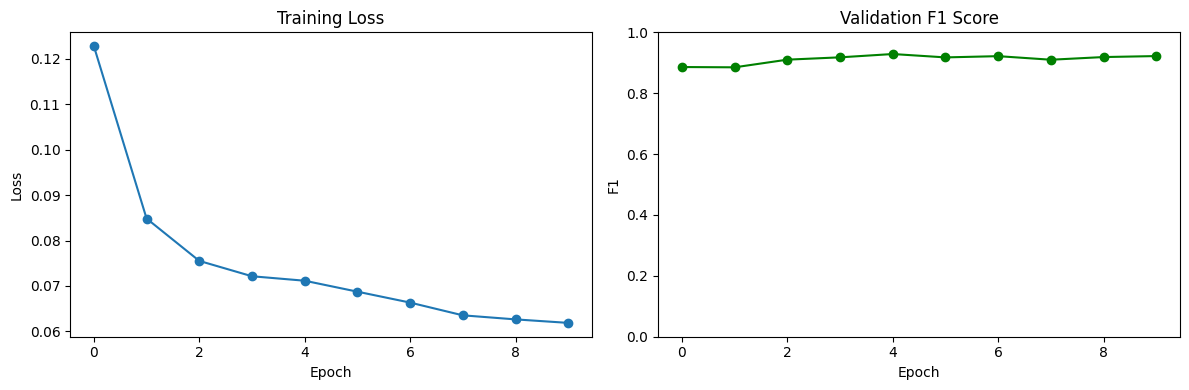

In [12]:
import os

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, marker='o')
ax1.set_title("Training Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")

ax2.plot(val_f1s, marker='o', color='green')
ax2.set_title("Validation F1 Score")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("F1")
ax2.set_ylim(0, 1)

plt.tight_layout()

os.makedirs("../results", exist_ok=True)
plt.savefig("../results/training_curves.png", dpi=150, bbox_inches='tight')
plt.show()

## Final Evaluation

In [13]:
from sklearn.metrics import classification_report

model.eval()
preds = []
targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        output = model(X_batch.to(device))
        preds.extend(output.argmax(1).cpu().numpy())
        targets.extend(y_batch.numpy())

print(classification_report(targets, preds, digits=4, target_names=["Benign", "Attack"]))

              precision    recall  f1-score   support

      Benign     0.9983    0.9655    0.9816    129594
      Attack     0.8604    0.9921    0.9216     27767

    accuracy                         0.9702    157361
   macro avg     0.9293    0.9788    0.9516    157361
weighted avg     0.9739    0.9702    0.9710    157361



## Saving the model

In [14]:
import pickle

os.makedirs("../results", exist_ok=True)

# Saving the model weights
torch.save(model.state_dict(), "../results/threat_detector.pth")

# Save the scaler - needed later to preprocess inputs consistently
with open("../results/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# Save the exact split so the attack/defense notebooks evaluate on the same held-out test set
np.savez("../results/data_split.npz",
         X_train=X_train, y_train=y_train,
         X_test=X_test, y_test=y_test)
print("Data split saved to results/data_split.npz")

print("Model saved to results/threat_detector.pth")
print("Scaler saved to results/scaler.pkl")

Data split saved to results/data_split.npz
Model saved to results/threat_detector.pth
Scaler saved to results/scaler.pkl
